In [1]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# data

data= sns.load_dataset('flights')

In [3]:
data.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [5]:
data.shape

(144, 3)

In [9]:
# now we will change this dataset uning pivot --
# Signature: data.pivot(*, columns, index=<no_default>, values=<no_default>) -> 'DataFrame'

df = data.pivot(columns='year', index='month',values='passengers')

In [11]:
df.head()

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112,115,145,171,196,204,242,284,315,340,360,417
Feb,118,126,150,180,196,188,233,277,301,318,342,391
Mar,132,141,178,193,236,235,267,317,356,362,406,419
Apr,129,135,163,181,235,227,269,313,348,348,396,461
May,121,125,172,183,229,234,270,318,355,363,420,472


In [12]:
# we have done this cause to plot heatmap we need numerical data points

# Heatmap

<Axes: xlabel='year', ylabel='month'>

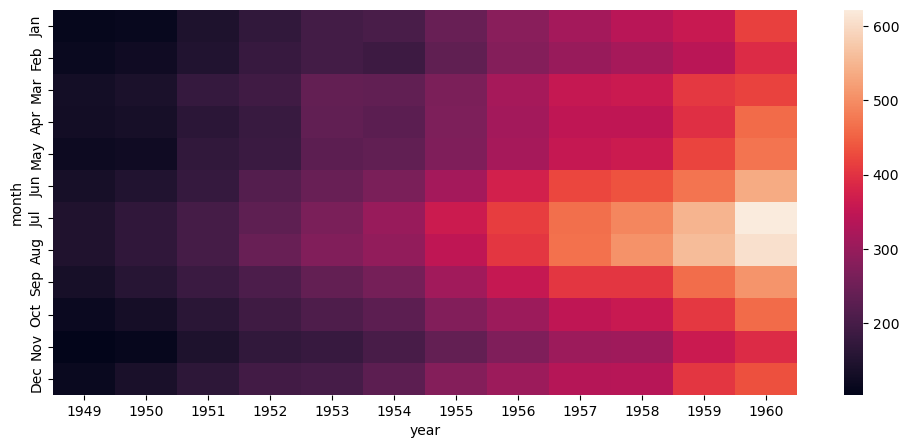

In [14]:
plt.figure(figsize=(12,5))

sns.heatmap(df)

<Axes: xlabel='year', ylabel='month'>

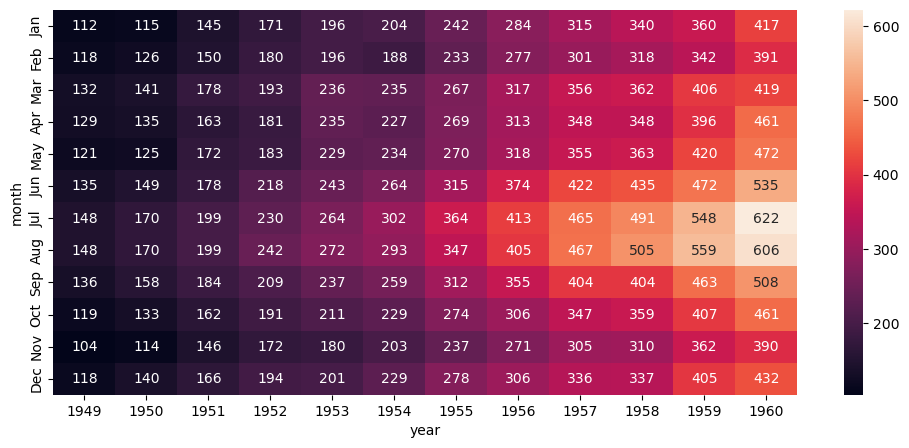

In [19]:
# now to also add the cell value in each cell -- annot=True, fmt='d '--> fmt is for format

plt.figure(figsize=(12,5))

sns.heatmap(df, annot=True, fmt='d')

<Axes: xlabel='year', ylabel='month'>

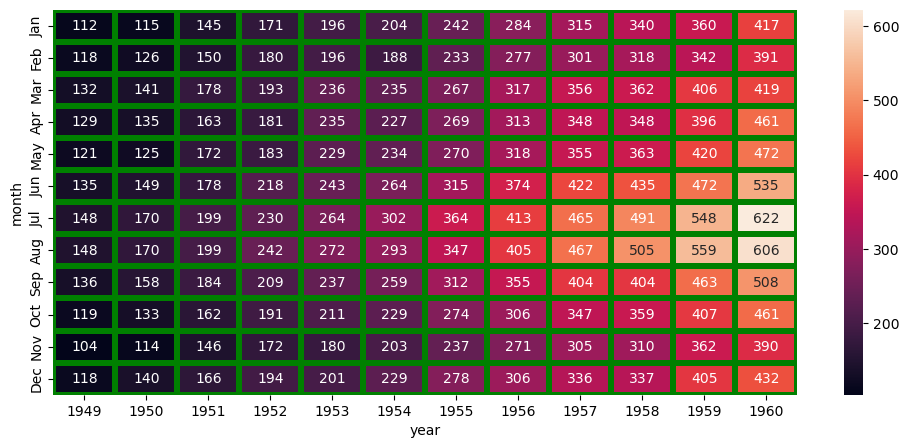

In [24]:
# now linecolor and linewidth --> space between each cells

plt.figure(figsize=(12,5))

sns.heatmap(df, annot=True, fmt='d',
           linecolor='green',linewidths='3')

<Axes: xlabel='year', ylabel='month'>

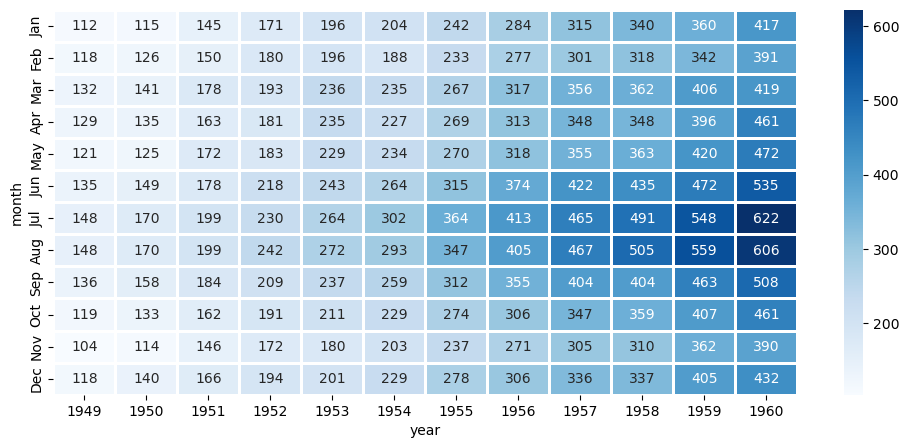

In [27]:
# lets change color

plt.figure(figsize=(12,5))

sns.heatmap(df, annot=True, fmt='d',
           linecolor='white',linewidths='1',
           cmap='Blues')

<Axes: xlabel='year', ylabel='month'>

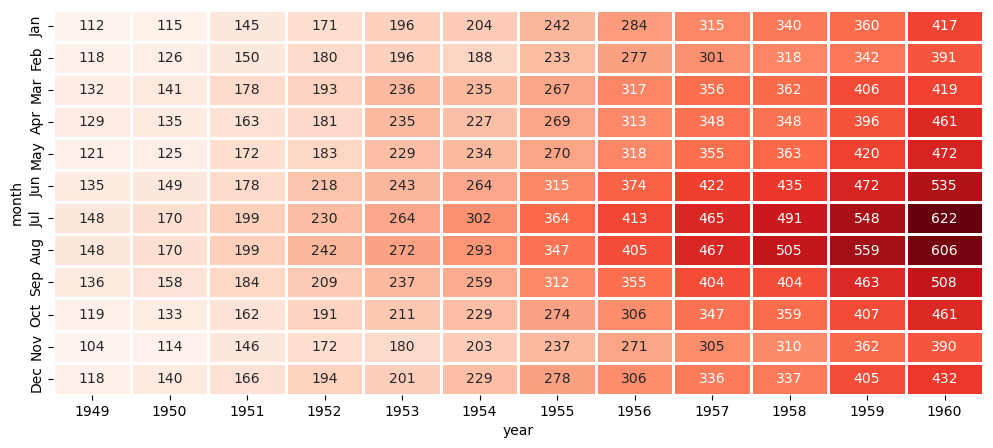

In [32]:
plt.figure(figsize=(12,5))

sns.heatmap(df, annot=True, fmt='d',
           linecolor='white',linewidths='1',
           cmap='Reds', cbar=False)

/var/folders/jd/5681g6rx58xgpr8txbqb17p80000gn/T/ipykernel_36397/951248278.py:27: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to prevent title overlap


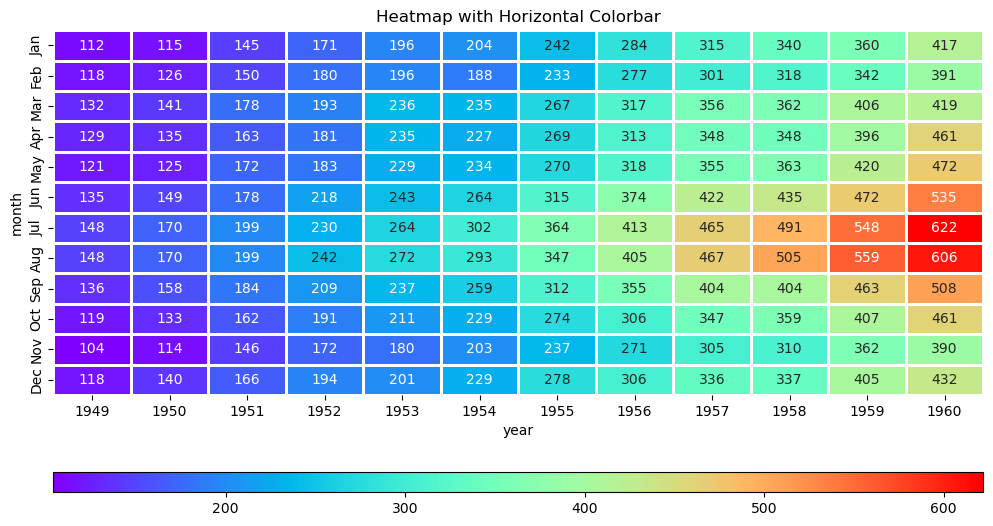

In [35]:
# cbar at bottom

# 1. Define the grid layout for the main plot and the colorbar.
# The 'height_ratios' will create two rows: a tall one for the heatmap
# and a short one for the colorbar.
grid_kws = {"height_ratios": (.9, .05), "hspace": .4}

# 2. Create the figure and axes using plt.subplots().
# We create 2 rows and 1 column. We unpack the two axes into `ax` (for the heatmap)
# and `cbar_ax` (for the colorbar).
fig, (ax, cbar_ax) = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw=grid_kws)

# 3. Plot the heatmap on the main axis (`ax`).
# Crucially, we set `cbar=False` to prevent the heatmap from drawing its own colorbar.
sns.heatmap(df, annot=True, fmt='.0f',
            linecolor='white', linewidths=1,
            cmap='rainbow', ax=ax, cbar=False)

# 4. Create the colorbar separately on the `cbar_ax`.
# We pass the `ax.collections[0]` to get the data for the colorbar.
fig.colorbar(ax.collections[0], cax=cbar_ax, orientation="horizontal")

# 5. Final plot adjustments.
ax.set_title('Heatmap with Horizontal Colorbar')
ax.set_ylabel('month')
ax.set_xlabel('year')
plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to prevent title overlap
plt.show()

<Axes: xlabel='year', ylabel='month'>

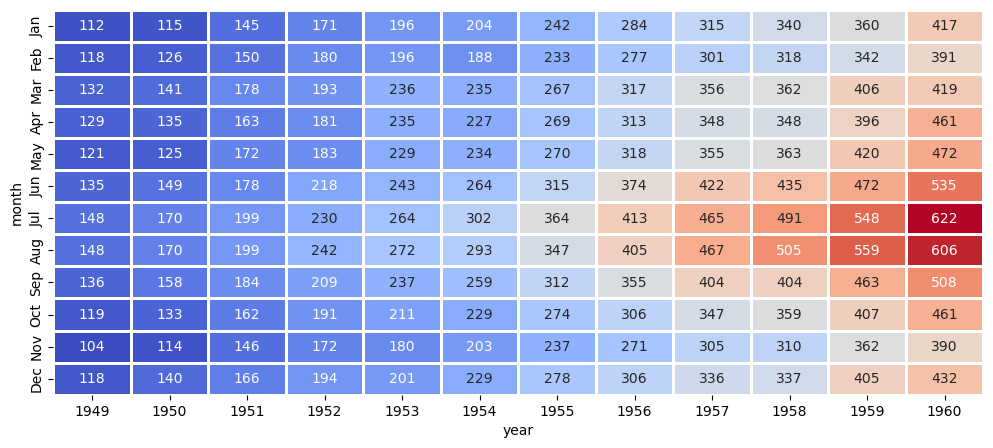

In [31]:
# to hide or show the bar at right

plt.figure(figsize=(12,5))

sns.heatmap(df, annot=True, fmt='d',
           linecolor='white',linewidths='1',
           cmap='coolwarm')

# Heatmaps are genreally also used to see corr() in data analysis in EDA

In [36]:
data2 = sns.load_dataset('titanic')

In [37]:
data2.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<Axes: >

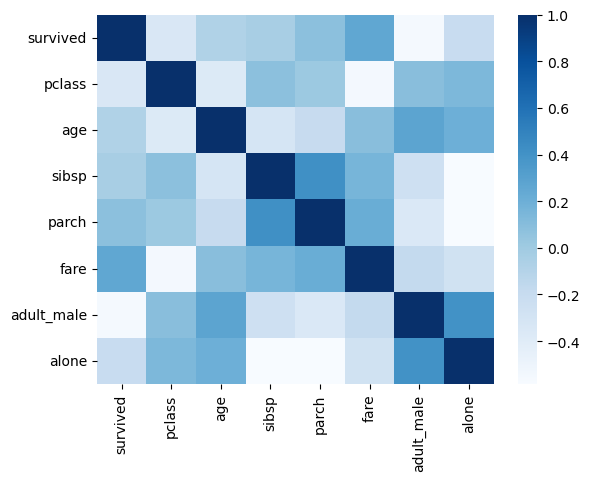

In [39]:
sns.heatmap(data2.corr(numeric_only=True), 
           cmap='Blues')

In [40]:
data2.corr(numeric_only=True)

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,-0.557080,-0.203367
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.094035,0.135207
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,0.280328,0.198270
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,-0.253586,-0.584471
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,-0.349943,-0.583398
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,-0.182024,-0.271832
adult_male,-0.557080,0.094035,0.280328,-0.253586,-0.349943,-0.182024,1.000000,0.404744
alone,-0.203367,0.135207,0.198270,-0.584471,-0.583398,-0.271832,0.404744,1.000000
